# Experimental ecological 3D views of a BIOMASS tomogram

This notebook is a sandbox: all experimental transformations remain here and are **not yet part of the `tomo_canopy` API**. It uses a verified real TOM/LVIS overlap to compare three visual ideas:

1. TOM scattering power as a conventional volume.
2. Strong-scattering voxels coloured by height above ground.
3. SH50/SH90 scattering-height surfaces compared with LVIS RH50/RH98.

SH means cumulative scattering height, not vegetation height. These are exploratory structural proxies—not biomass, vegetation density, or calibrated canopy products. Install dependencies with `python -m pip install -e '.[tomogram,lvis,examples,visualisation]'`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv

from tomo_canopy.processors import LVISProcessor, TomogramProcessor

pv.set_jupyter_backend("client")  # use "static" if Trame is unavailable

## Load a real, valid overlap

The subset was checked for finite TOM samples and dense LVIS coverage. Heights from −10 to 60 m are retained so that the ground-region response remains visible.

In [2]:
project_root = next(
    path for path in (Path.cwd(), Path.cwd().parent)
    if (path / "pyproject.toml").exists()
)
tom_source = next((project_root / "data" / "TOM").glob("*L2A*"))
lvis_source = (
    project_root / "data" / "lvisc" / "raw"
    / "LVISC2_Gabon2023_0520_R2507_055255.TXT"
)
bounds = (11.480, -0.080, 11.500, -0.060)

tom_processor = TomogramProcessor()
tom = tom_processor.open(
    tom_source, expected_level="L2A", polarization="HV",
    height_range=(-10, 60), bounds=bounds, chunks="auto",
)
tom = tom_processor.to_power(tom).load()
power = tom.tomographic_power.sel(polarization="HV")

finite_fraction = float(np.isfinite(power).sum() / power.size)
assert finite_fraction > 0.95, f"Unexpected TOM coverage: {finite_fraction:.1%}"
tom.sizes, finite_fraction

(Frozen({'polarization': 1, 'z': 36, 'y': 48, 'x': 48}), 1.0)

## Prototype vertical structural proxies

The product samples height every 2 m, but sampling is not physical resolution. For this visual experiment, a 20 m centred rolling mean suppresses unsupported fine vertical layering. We then normalize each column and derive cumulative scattering heights, centroid, entropy, and stratum fractions. The boxcar smoother is only a visual approximation of effective resolution.

In [3]:
vertical_sampling = float(np.median(np.diff(power.z.values)))
nominal_vertical_resolution = 20.0
window = max(1, round(nominal_vertical_resolution / vertical_sampling))
smoothed = power.rolling(z=window, center=True, min_periods=1).mean()
values = np.asarray(smoothed.values, dtype=float)  # (z, y, x)
z = np.asarray(smoothed.z.values, dtype=float)

total = np.nansum(values, axis=0)
valid = np.isfinite(values).any(axis=0) & (total > 0)
profile = np.divide(
    values, total[None, ...],
    out=np.full_like(values, np.nan), where=valid[None, ...],
)
cdf = np.cumsum(np.nan_to_num(profile, nan=0.0), axis=0)

def scattering_height(quantile):
    index = np.argmax(cdf >= quantile, axis=0)
    result = z[index].astype(float)
    result[~valid] = np.nan
    return result

sh50 = scattering_height(0.50)
sh90 = scattering_height(0.90)
centroid = np.nansum(profile * z[:, None, None], axis=0)
centroid[~valid] = np.nan
log_profile = np.zeros_like(profile)
np.log(profile, out=log_profile, where=profile > 0)
entropy = -np.nansum(profile * log_profile, axis=0) / np.log(len(z))
entropy[~valid] = np.nan
lower_fraction = np.nansum(profile[(z >= 0) & (z < 10)], axis=0)
middle_fraction = np.nansum(profile[(z >= 10) & (z < 30)], axis=0)
upper_fraction = np.nansum(profile[z >= 30], axis=0)
window, np.nanmin(sh90), np.nanmax(sh90)

(10, np.float64(18.0), np.float64(60.0))

## Inspect the proxies in 2D first

A 2D diagnostic makes numerical problems much easier to identify than a volume renderer. Missing cells should remain blank.

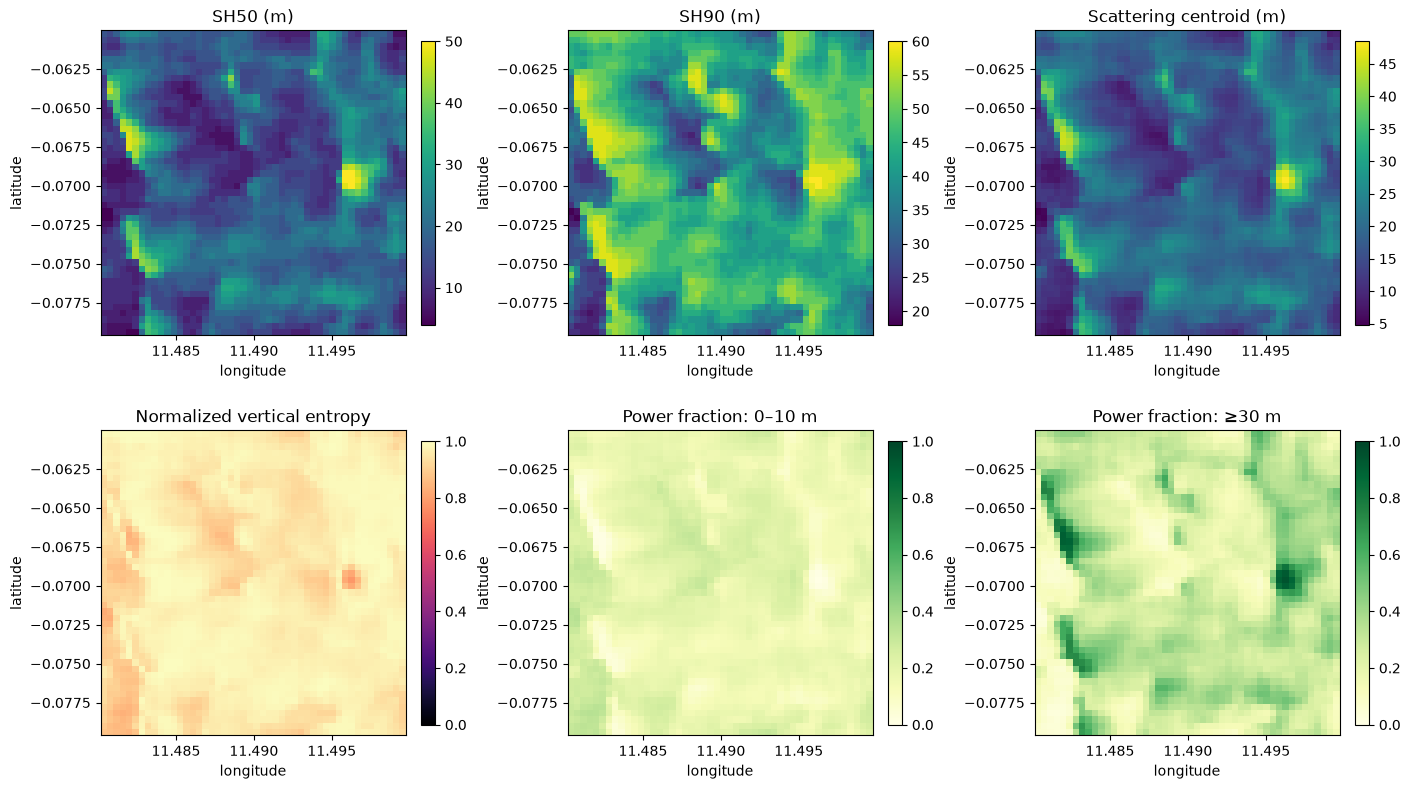

In [4]:
extent = [float(tom.x.min()), float(tom.x.max()), float(tom.y.min()), float(tom.y.max())]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
panels = [
    (sh50, "SH50 (m)", "viridis", None, None),
    (sh90, "SH90 (m)", "viridis", None, None),
    (centroid, "Scattering centroid (m)", "viridis", None, None),
    (entropy, "Normalized vertical entropy", "magma", 0, 1),
    (lower_fraction, "Power fraction: 0–10 m", "YlGn", 0, 1),
    (upper_fraction, "Power fraction: ≥30 m", "YlGn", 0, 1),
]
for ax, (image, title, cmap, vmin, vmax) in zip(axes.flat, panels):
    artist = ax.imshow(image, origin="lower", extent=extent, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title); ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
    fig.colorbar(artist, ax=ax, shrink=0.8)
plt.show()

## Convert geographic coordinates to local metres

This local approximation is adequate for the small display window and prevents degrees horizontally from being mixed with metres vertically. It is a display transform, not a replacement for formal reprojection.

In [5]:
lon0, lat0 = float(tom.x.mean()), float(tom.y.mean())
metres_per_degree_lon = 111_320.0 * np.cos(np.deg2rad(lat0))
metres_per_degree_lat = 111_132.0
to_local_x = lambda longitude: (np.asarray(longitude) - lon0) * metres_per_degree_lon
to_local_y = lambda latitude: (np.asarray(latitude) - lat0) * metres_per_degree_lat
x_m, y_m = to_local_x(tom.x), to_local_y(tom.y)
xx, yy = np.meshgrid(x_m, y_m, indexing="xy")

## View A — conventional scattering volume

This is closest to the measurement. The scene uses log-power contrast and a nonlinear opacity transfer so weak background values remain transparent. Because the subset is about 2.2 km wide but only 70 m tall, height is exaggerated 12× for inspection; the underlying height values remain metres. Three reference slices and two isosurfaces help reveal structure that a volume alone can hide. This view is useful scientifically but is not automatically an ecological volume.

In [ ]:
volume = np.transpose(values, (2, 1, 0))  # x, y, z for VTK
with np.errstate(divide="ignore", invalid="ignore"):
    volume_db = 10 * np.log10(volume)
low, high = np.nanpercentile(volume_db, [10, 99.7])
scaled = np.clip((volume_db - low) / (high - low), 0, 1)
scaled[~np.isfinite(scaled)] = np.nan

vertical_exaggeration = 12
z_display = z * vertical_exaggeration
grid = pv.RectilinearGrid(x_m, y_m, z_display)
grid.point_data["relative HV power"] = scaled.ravel(order="F")
opacity = np.zeros(256)
opacity[90:] = np.linspace(0.0, 0.65, 166) ** 1.5

plotter = pv.Plotter(notebook=True, window_size=(1100, 750))
plotter.set_background("#10151c")
plotter.add_volume(
    grid, scalars="relative HV power", cmap="magma",
    opacity=opacity, clim=(0, 1), shade=False,
)
for normal, origin in [
    ("x", (0, 0, 20 * vertical_exaggeration)),
    ("y", (0, 0, 20 * vertical_exaggeration)),
    ("z", (0, 0, 20 * vertical_exaggeration)),
]:
    plotter.add_mesh(
        grid.slice(normal=normal, origin=origin),
        scalars="relative HV power", cmap="magma", clim=(0, 1),
        opacity=0.55, show_scalar_bar=False,
    )
contours = grid.contour([0.70, 0.85], scalars="relative HV power")
plotter.add_mesh(contours, scalars="relative HV power", cmap="magma", clim=(0, 1), opacity=0.35)
plotter.add_mesh(
    pv.Plane(center=(0, 0, 0), i_size=np.ptp(x_m), j_size=np.ptp(y_m)),
    color="tan", opacity=0.18,
)
plotter.add_text("HV scattering power — height exaggerated 12×", font_size=11)
plotter.show_grid(xtitle="east (m)", ytitle="north (m)", ztitle="display height (12×)")
plotter.camera_position = "iso"
plotter.show()

Widget(value='<iframe src="http://localhost:36177/index.html?ui=P_0x77d0e0b6ab10_0&reconnect=auto" class="pyvi…

JS Error => no webgl context
JS Error => TypeError: Cannot create proxy with a non-object as target or handler
JS Error => no webgl context
JS Error => TypeError: Cannot create proxy with a non-object as target or handler
JS Error => no webgl context
JS Error => TypeError: Cannot create proxy with a non-object as target or handler


## View B — height-coloured scattering structure

Only voxels in the strongest 20% of **each column's** normalized vertical profile are shown. Colour represents height—not power—so the distribution of lower, middle, and upper scattering is immediately visible. Height is exaggerated 12×. The threshold is intentionally exploratory and should not become a scientific default without evaluation.

In [7]:
column_threshold = np.nanquantile(profile, 0.80, axis=0)
keep = np.isfinite(profile) & (profile >= column_threshold[None, ...])
iz, iy, ix = np.where(keep)
view_b_vertical_exaggeration = 12
points = pv.PolyData(np.column_stack([
    x_m[ix], y_m[iy], z[iz] * view_b_vertical_exaggeration,
]))
points["height above ground (m)"] = z[iz]
points["profile contribution"] = profile[iz, iy, ix]

plotter = pv.Plotter(notebook=True, window_size=(1100, 750))
plotter.set_background("#10151c")
plotter.add_mesh(
    points, scalars="height above ground (m)", cmap="terrain",
    render_points_as_spheres=True, point_size=6, opacity=0.35,
)
plotter.add_mesh(pv.Plane(center=(0, 0, 0), i_size=np.ptp(x_m), j_size=np.ptp(y_m)), color="tan", opacity=0.35)
plotter.add_text("Column-relative scattering — height exaggerated 12×", font_size=11)
plotter.show_grid(xtitle="east (m)", ytitle="north (m)", ztitle="display height (12×)")
plotter.camera_position = "iso"
plotter.show()

Widget(value='<iframe src="http://localhost:36177/index.html?ui=P_0x77d094341a90_1&reconnect=auto" class="pyvi…

## View B2 — vertical transect with LVIS heights

The 3D overview is useful for orientation but weak for reading vertical organisation. This curtain averages a narrow east–west corridor through the TOM profile and preserves the full vertical distribution. TOM SH50/SH90 and nearby LVIS RH50/RH98 are overlaid in their original metre units—there is no vertical exaggeration in this plot.

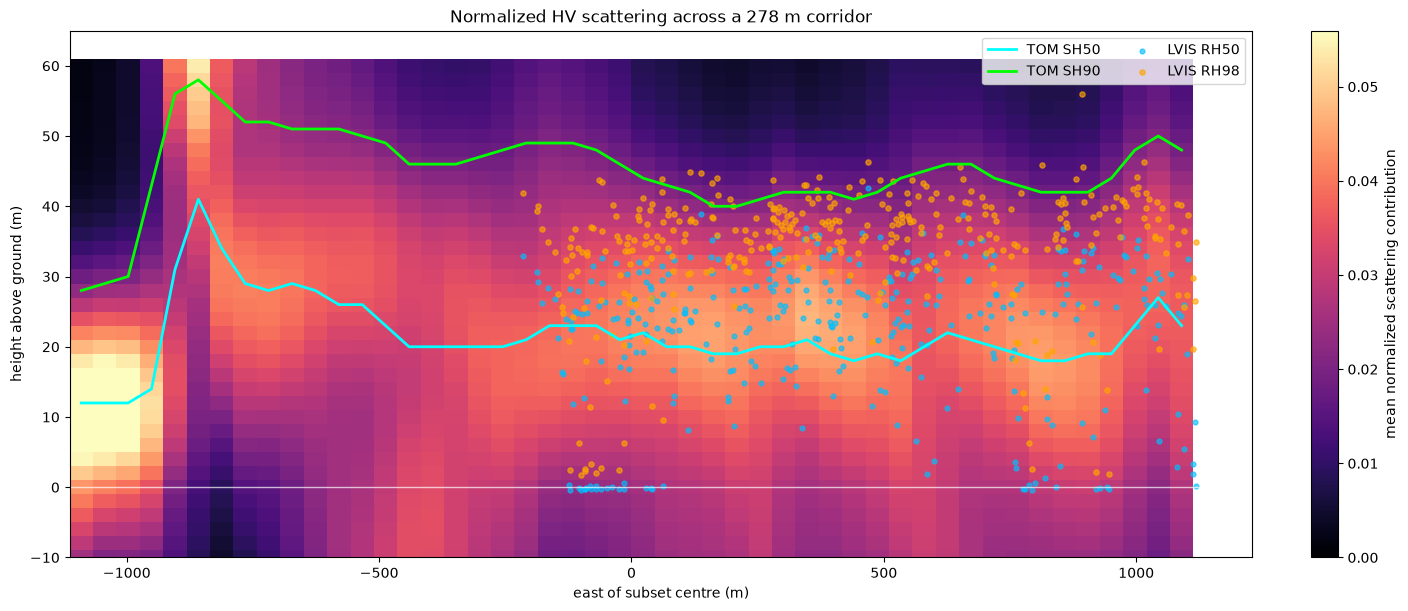

In [8]:
lvis_processor = LVISProcessor()
lvis = lvis_processor.open(
    lvis_source, variables=["rh", "sensitivity"],
    bounds=bounds, max_shots=5000,
)
lvis = lvis_processor.filter_quality(
    lvis, minimum_sensitivity=0.9, require_finite_rh=True,
)
lvis = lvis_processor.add_rh_metric(lvis, percentile=50)
lvis = lvis_processor.add_rh_metric(lvis, percentile=98)
lvis = lvis_processor.sample_shots(lvis, count=1500, seed=42)

lvis_x = to_local_x(lvis.longitude)
lvis_y = to_local_y(lvis.latitude)
transect_y = float(np.median(lvis_y))
pixel_width = float(np.median(np.diff(y_m)))
corridor_half_width = max(60.0, 3 * abs(pixel_width))
tom_corridor = np.abs(y_m - transect_y) <= corridor_half_width
lvis_corridor = np.abs(lvis_y - transect_y) <= corridor_half_width
assert tom_corridor.any() and lvis_corridor.any(), "Transect misses TOM or LVIS data"

transect_profile = np.nanmean(profile[:, tom_corridor, :], axis=1)
sh50_line = np.nanmedian(sh50[tom_corridor, :], axis=0)
sh90_line = np.nanmedian(sh90[tom_corridor, :], axis=0)
vmax = np.nanpercentile(transect_profile, 99)

fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
image = ax.pcolormesh(
    x_m, z, transect_profile, shading="auto", cmap="magma",
    vmin=0, vmax=vmax,
)
ax.plot(x_m, sh50_line, color="cyan", linewidth=2, label="TOM SH50")
ax.plot(x_m, sh90_line, color="lime", linewidth=2, label="TOM SH90")
order = np.argsort(lvis_x[lvis_corridor])
ax.scatter(
    lvis_x[lvis_corridor][order], lvis.rh50.values[lvis_corridor][order],
    s=12, color="deepskyblue", alpha=0.65, label="LVIS RH50",
)
ax.scatter(
    lvis_x[lvis_corridor][order], lvis.rh98.values[lvis_corridor][order],
    s=14, color="orange", alpha=0.65, label="LVIS RH98",
)
ax.axhline(0, color="white", linewidth=1, alpha=0.7)
ax.set(xlabel="east of subset centre (m)", ylabel="height above ground (m)", ylim=(-10, 65))
ax.set_title(f"Normalized HV scattering across a {2*corridor_half_width:.0f} m corridor")
ax.legend(loc="upper right", ncols=2)
fig.colorbar(image, ax=ax, label="mean normalized scattering contribution")
plt.show()

## View B3 — inspect individual vertical profiles

Three profiles along the transect expose ground response, broad or concentrated canopy scattering, and possible multiple peaks. Dashed lines show TOM cumulative scattering heights; dotted lines show the nearest displayed LVIS footprint. This is the most direct diagnostic before assigning ecological labels.

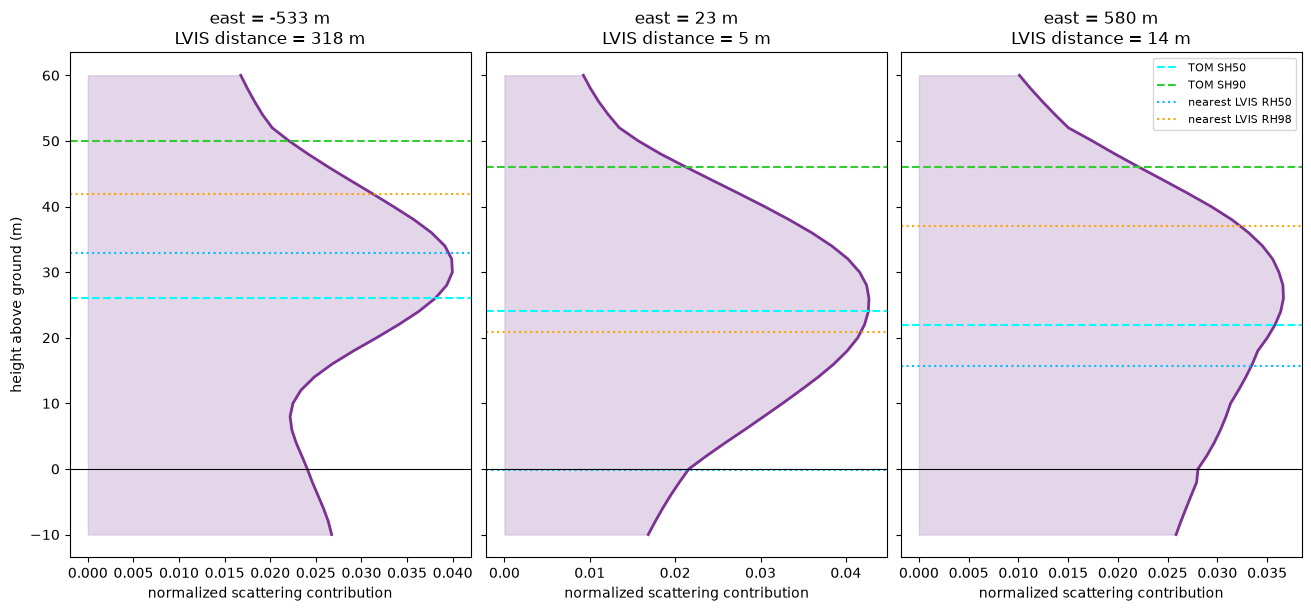

In [9]:
transect_y_index = int(np.argmin(np.abs(y_m - transect_y)))
profile_x_indices = [len(x_m) // 4, len(x_m) // 2, 3 * len(x_m) // 4]
fig, axes = plt.subplots(1, 3, figsize=(13, 6), sharey=True, constrained_layout=True)

for ax, x_index in zip(axes, profile_x_indices):
    vertical_profile = profile[:, transect_y_index, x_index]
    ax.plot(vertical_profile, z, color="#7b3294", linewidth=2)
    ax.fill_betweenx(z, 0, vertical_profile, color="#c2a5cf", alpha=0.45)
    ax.axhline(sh50[transect_y_index, x_index], color="cyan", linestyle="--", label="TOM SH50")
    ax.axhline(sh90[transect_y_index, x_index], color="limegreen", linestyle="--", label="TOM SH90")
    distance = np.hypot(lvis_x - x_m[x_index], lvis_y - y_m[transect_y_index])
    nearest = int(np.argmin(distance))
    ax.axhline(float(lvis.rh50.values[nearest]), color="deepskyblue", linestyle=":", label="nearest LVIS RH50")
    ax.axhline(float(lvis.rh98.values[nearest]), color="orange", linestyle=":", label="nearest LVIS RH98")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(f"east = {x_m[x_index]:.0f} m\nLVIS distance = {distance[nearest]:.0f} m")
    ax.set_xlabel("normalized scattering contribution")
axes[0].set_ylabel("height above ground (m)")
axes[-1].legend(loc="upper right", fontsize=8)
plt.show()

## View C — scattering envelopes with LVIS validation

SH50 and SH90 form compact structural envelopes. LVIS RH50 and RH98 points provide an independent lidar comparison, but they are not expected to coincide exactly: footprint size, acquisition time, physical observable, and effective resolution differ.

In [10]:
lvis_processor = LVISProcessor()
lvis = lvis_processor.open(
    lvis_source, variables=["rh", "sensitivity"],
    bounds=bounds, max_shots=5000,
)
lvis = lvis_processor.filter_quality(lvis, minimum_sensitivity=0.9, require_finite_rh=True)
lvis = lvis_processor.add_rh_metric(lvis, percentile=50)
lvis = lvis_processor.add_rh_metric(lvis, percentile=98)
lvis = lvis_processor.sample_shots(lvis, count=350, seed=42)

surface50 = pv.StructuredGrid(xx, yy, sh50)
surface90 = pv.StructuredGrid(xx, yy, sh90)
surface90["upper-canopy power fraction"] = upper_fraction.ravel(order="F")
shot_x, shot_y = to_local_x(lvis.longitude), to_local_y(lvis.latitude)
rh50_points = pv.PolyData(np.column_stack([shot_x, shot_y, lvis.rh50.values]))
rh98_points = pv.PolyData(np.column_stack([shot_x, shot_y, lvis.rh98.values]))

plotter = pv.Plotter(notebook=True)
plotter.add_mesh(surface50, color="royalblue", opacity=0.35, label="TOM SH50")
plotter.add_mesh(
    surface90, scalars="upper-canopy power fraction", cmap="YlGn",
    clim=(0, 1), opacity=0.60, label="TOM SH90",
)
plotter.add_mesh(rh50_points, color="cyan", point_size=7, render_points_as_spheres=True, label="LVIS RH50")
plotter.add_mesh(rh98_points, color="orange", point_size=8, render_points_as_spheres=True, label="LVIS RH98")
plotter.add_mesh(pv.Plane(center=(0, 0, 0), i_size=np.ptp(x_m), j_size=np.ptp(y_m)), color="tan", opacity=0.25)
plotter.add_legend(); plotter.show_grid(); plotter.camera_position = "iso"
plotter.show()

Widget(value='<iframe src="http://localhost:36177/index.html?ui=P_0x77d07c1f7620_2&reconnect=auto" class="pyvi…

## What to evaluate before moving code into the package

Compare which view is understandable without over-interpreting the measurement. Test sensitivity to the smoothing width, selected polarization, ground reference, voxel threshold, and cumulative-height definition. If SH surfaces are useful, compare spatially aggregated SH50/SH90 against LVIS RH50/RH98 before naming or exposing a stable ecological transform.